In [53]:
from src import utils
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, clear_output

root = Path.cwd().parent
data_dir = root / "data"

In [54]:
anchors = np.loadtxt(data_dir / "anchorsII.dat")
ranges = np.loadtxt(data_dir / "rangesII.dat")
checkpoints = np.loadtxt(data_dir / "checkpointsII.dat")

checkpoints = checkpoints[:, 1:]

print(anchors.shape)
print(ranges.shape)
print(checkpoints.shape)

for i in range(3):
    H = utils.hessian(anchors[i], anchors, ranges[0])
    print(f"Anchor {i+1}:")
    print("Hessian =", H)

(3, 2)
(60, 3)
(6, 2)
Anchor 1:
Hessian = [[263.69281078   4.        ]
 [  4.          14.01281078]]
Anchor 2:
Hessian = [[ 38.85281078   0.        ]
 [  0.         -60.50718922]]
Anchor 3:
Hessian = [[263.69281078  -4.        ]
 [ -4.          14.01281078]]


In [55]:
C = 2 * (anchors[1:] - anchors[0])

p_LLS_list = []
p_gd_list = []

for t, r in enumerate(ranges):
    d_t = r[0]**2 - r[1:]**2 + np.sum(anchors[1:]**2, axis=1) - np.sum(anchors[0]**2)
    p_LLS_t = utils.naive_LSE(C, d_t)

    p_init = p_LLS_t
    iter_cnt, p_gd_t, final_loss = utils.g_gd(t, p_init, anchors, ranges)
    print(f"t={t+1} | iterations:{iter_cnt}, loss={final_loss}")

    p_LLS_list.append(p_LLS_t)
    p_gd_list.append(p_gd_t)

p_LLS_list = np.array(p_LLS_list)
p_gd_list = np.array(p_gd_list)

t=1 | iterations:1094, loss=0.175847833067514
t=2 | iterations:903, loss=0.019980145347655277
t=3 | iterations:947, loss=0.16685494604655216
t=4 | iterations:709, loss=0.4596501520206526
t=5 | iterations:539, loss=0.0005124395804460498
t=6 | iterations:552, loss=0.01985689624552276
t=7 | iterations:500, loss=0.07829293522013905
t=8 | iterations:495, loss=1.202917239482269
t=9 | iterations:502, loss=0.38195497269696604
t=10 | iterations:412, loss=0.012698359923141762
t=11 | iterations:367, loss=0.0910060458574683
t=12 | iterations:353, loss=0.0730444286156361
t=13 | iterations:358, loss=0.45527185798527914
t=14 | iterations:329, loss=1.5628465133153835
t=15 | iterations:334, loss=0.2002305862195605
t=16 | iterations:337, loss=0.07609340731426473
t=17 | iterations:270, loss=0.0021109208262304405
t=18 | iterations:289, loss=0.01955995346067899
t=19 | iterations:301, loss=0.28815156646250106
t=20 | iterations:292, loss=0.044114928898980436
t=21 | iterations:271, loss=0.031380529367578756
t

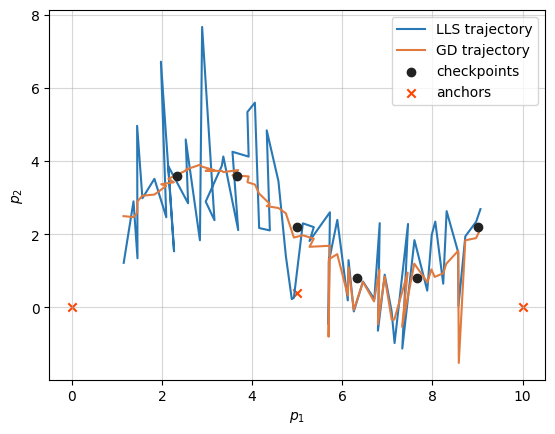

In [56]:
plt.plot(p_LLS_list[:, 0], p_LLS_list[:, 1], label="LLS trajectory", color="#2878B5")
plt.plot(p_gd_list[:, 0], p_gd_list[:, 1], label="GD trajectory", color="#E07A3F")
plt.scatter(checkpoints[:, 0], checkpoints[:, 1], label="checkpoints", zorder=10, color="#222222")
plt.scatter(anchors[:, 0], anchors[:, 1], label="anchors", marker="x", color="#FF4500")

plt.grid(alpha=0.5)
plt.xlabel(r"$p_1$")
plt.ylabel(r"$p_2$")
plt.legend()

In [57]:
print(f"kappa(C'C)={utils.get_condition_number(C.T @ C)}")
print(f"LLS: E_ck={utils.valid(p_LLS_list, checkpoints)}")
print(f"GD: E_ck={utils.valid(p_gd_list, checkpoints)}")

kappa(C'C)=977.0630765246233
LLS: E_ck=1.0387059385597825
GD: E_ck=0.42534333650551737


In [58]:
jumps = np.where(p_gd_list[:, 1] < 0)[0]
print(jumps+1)

# jumps = np.array([34, 35, 36, 39, 40, 41, 43, 44, 45, 46, 47, 48, 49, 50, 56, 57, 58])
# jumps -= 1

# n = len(jumps)
# ncols = 3
# nrows = int(np.ceil(n / ncols))

# fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
# axes = np.array(axes).flatten()

# x = np.linspace(0, 10, 500)
# y = np.linspace(-6, 6, 500)
# X, Y = np.meshgrid(x, y)

# for k, jump in enumerate(jumps):
#     Z = np.zeros_like(X)
#     minZ = 10000
#     minx = None
#     miny = None
#     for i in range(X.shape[0]):
#         for j in range(X.shape[1]):
#             Z[i, j] = utils.g(jump, np.array([X[i,j], Y[i,j]]), anchors, ranges)
#             if Z[i, j] < minZ:
#                 minZ = Z[i, j]
#                 minx = X[i, j]
#                 miny = Y[i, j]

#     axes[k].contourf(X, Y, Z, levels=50, cmap="viridis")
#     axes[k].scatter([minx], [miny], marker="x", color="red")
#     axes[k].grid(alpha=0.5)
#     axes[k].set_xlabel(r"$p_1$")
#     axes[k].set_ylabel(r"$p_2$")
#     axes[k].set_title(f"t={jump}")
#     fig.colorbar(axes[k].collections[0], ax=axes[k], label=r'$g_t(p)$')

# # Hide unused subplots
# for i in range(n, len(axes)):
#     axes[i].set_visible(False)

# plt.tight_layout()
# plt.show()

[35 40 44 46 47 49 57]


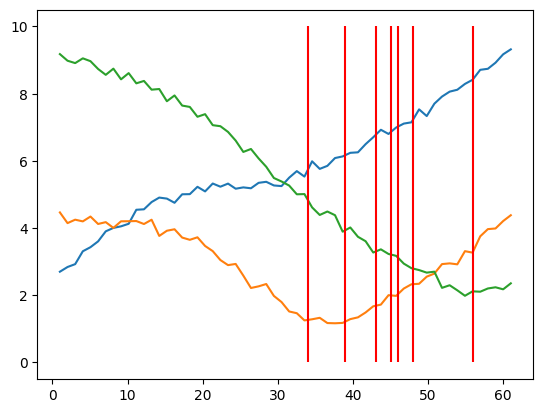

In [59]:
t_list = np.linspace(1, 61, 60)
plt.plot(t_list, ranges[:, 0])
plt.plot(t_list, ranges[:, 1])
plt.plot(t_list, ranges[:, 2])
plt.vlines(jumps, ymin=0, ymax=10, color="r")

In [60]:
T = ranges.shape[0]
s2 = anchors[1]

H = np.zeros((2, 2))

for t in range(T):
    H += utils.hessian(s2, anchors, ranges[t])

print("s2 =", s2)
print("Hessian at s2:")
print(H)
print("Eigenvalues:")
print(np.linalg.eigvalsh(H))

s2 = [5.  0.4]
Hessian at s2:
[[ 4062.52713435     0.        ]
 [    0.         -1899.07286565]]
Eigenvalues:
[-1899.07286565  4062.52713435]


In [61]:
lamb_set = np.array([0.1, 1, 10, 100, 1000])
P_track_list = []
valid_error_list = []
loss_list = []

for lamb in lamb_set:
    iter_cnt, P_gd, final_loss = utils.G_gd(lamb, p_gd_list, anchors, ranges)
    valid_error = utils.valid(P_gd, checkpoints)
    print(f"lambda={lamb} | iterations:{iter_cnt}, final_loss={final_loss}, valid_error={valid_error}")
    
    P_track_list.append(P_gd)
    valid_error_list.append(valid_error)
    loss_list.append(final_loss)

P_track_list = np.array(P_track_list)
valid_error_list = np.array(valid_error_list)
loss_list = np.array(loss_list)

lambda=0.1 | iterations:19797, final_loss=10.02429132350197, valid_error=0.2889976258484109
lambda=1.0 | iterations:11172, final_loss=12.177986655063894, valid_error=0.20862485003737402
lambda=10.0 | iterations:6823, final_loss=22.649374494757815, valid_error=0.14631018581228472
lambda=100.0 | iterations:4162, final_loss=98.6316032642359, valid_error=0.2252445077336914
lambda=1000.0 | iterations:8331, final_loss=669.456575975212, valid_error=0.46952868038183787


Text(0, 0.5, '$E_{ck}$')

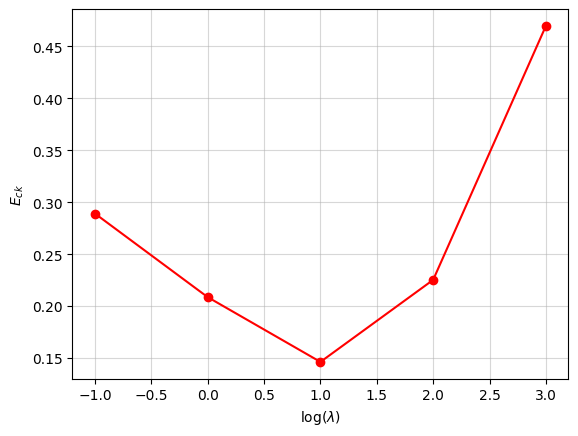

In [62]:
plt.plot(np.log10(lamb_set), valid_error_list, marker="o", color="r")
plt.grid(alpha=0.5)
plt.xlabel(r"$\log(\lambda)$")
plt.ylabel(r"$E_{ck}$")

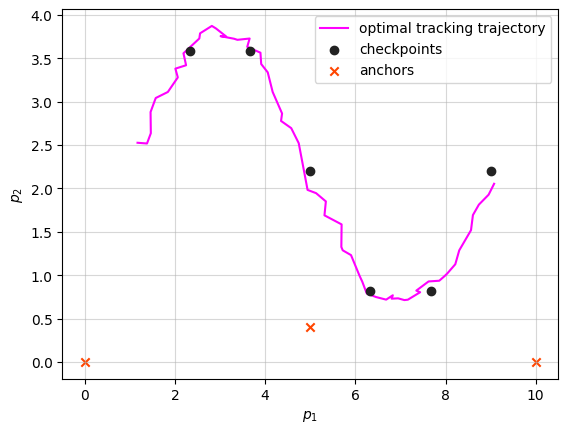

In [63]:
optimal_idx = np.argmin(valid_error_list)
optimal_traj = P_track_list[optimal_idx]

plt.plot(optimal_traj[:, 0], optimal_traj[:, 1], label="optimal tracking trajectory", color="magenta")
plt.scatter(checkpoints[:, 0], checkpoints[:, 1], label="checkpoints", zorder=10, color="#222222")
plt.scatter(anchors[:, 0], anchors[:, 1], label="anchors", marker="x", color="#FF4500")

plt.grid(alpha=0.5)
plt.xlabel(r"$p_1$")
plt.ylabel(r"$p_2$")
plt.legend()

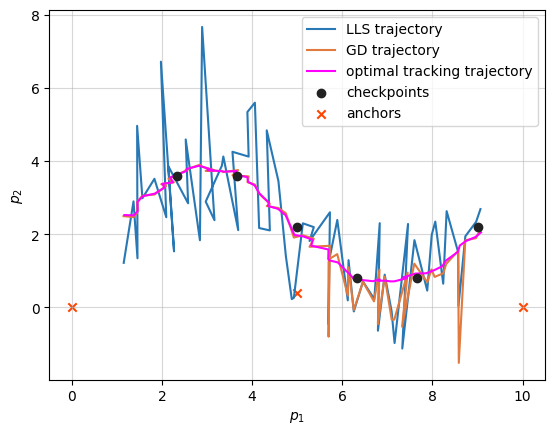

In [64]:
plt.plot(p_LLS_list[:, 0], p_LLS_list[:, 1], label="LLS trajectory", color="#2878B5")
plt.plot(p_gd_list[:, 0], p_gd_list[:, 1], label="GD trajectory", color="#E07A3F")
plt.plot(optimal_traj[:, 0], optimal_traj[:, 1], label="optimal tracking trajectory", color="magenta")
plt.scatter(checkpoints[:, 0], checkpoints[:, 1], label="checkpoints", zorder=10, color="#222222")
plt.scatter(anchors[:, 0], anchors[:, 1], label="anchors", marker="x", color="#FF4500")

plt.grid(alpha=0.5)
plt.xlabel(r"$p_1$")
plt.ylabel(r"$p_2$")
plt.legend()

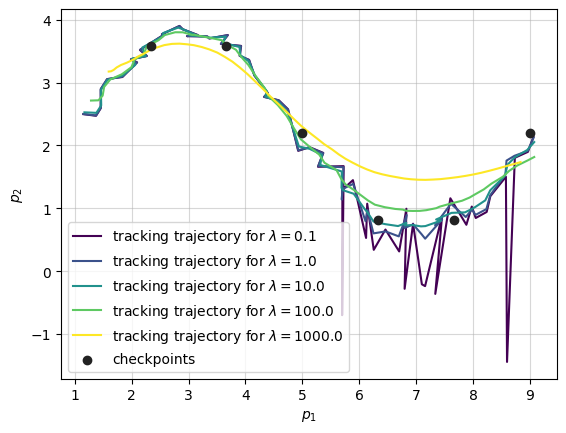

In [65]:
cmap = plt.get_cmap("viridis")

for idx, traj in enumerate(P_track_list):
    color = cmap(idx / (len(lamb_set) - 1))
    plt.plot(traj[:, 0], traj[:, 1], label=r"tracking trajectory for $\lambda=$" + f"{lamb_set[idx]}", color=color)

plt.scatter(checkpoints[:, 0], checkpoints[:, 1], label="checkpoints", zorder=10, color="#222222")

plt.grid(alpha=0.5)
plt.xlabel(r"$p_1$")
plt.ylabel(r"$p_2$")
plt.legend()

In [66]:
optimal_lamb = lamb_set[optimal_idx]
P_mirror = optimal_traj.copy()
P_mirror[:, 1] *= -1

_, mirror_result, mirror_loss = utils.G_gd(optimal_lamb, P_mirror, anchors, ranges)
mirror_valid_error = utils.valid(mirror_result, checkpoints)
print(f"optimal error:{valid_error_list[optimal_idx]}, mirrored error:{mirror_valid_error}")
print(f"optimal loss:{loss_list[optimal_idx]}, mirrored loss:{mirror_loss}")

optimal error:0.14631018581228472, mirrored error:4.628363547591994
optimal loss:22.649374494757815, mirrored loss:167.6738028119051


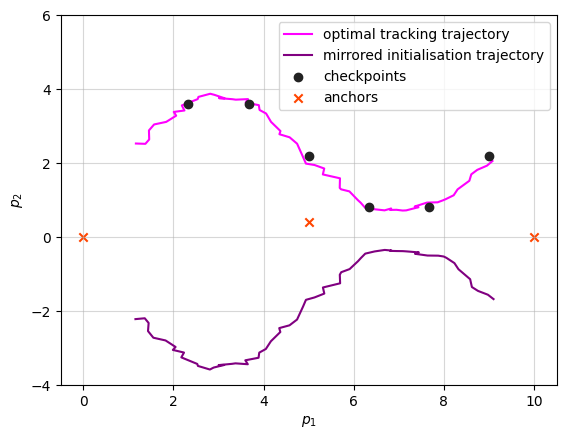

In [68]:
plt.plot(optimal_traj[:, 0], optimal_traj[:, 1], label="optimal tracking trajectory", color="magenta")
plt.plot(mirror_result[:, 0], mirror_result[:, 1], label="mirrored initialisation trajectory", color="purple")
plt.scatter(checkpoints[:, 0], checkpoints[:, 1], label="checkpoints", zorder=10, color="#222222")
plt.scatter(anchors[:, 0], anchors[:, 1], label="anchors", marker="x", color="#FF4500")

plt.grid(alpha=0.5)
plt.xlabel(r"$p_1$")
plt.ylabel(r"$p_2$")
plt.ylim((-4, 6))
plt.legend()